# 합성 결함(Cut & Paste) 추가 전/후 비교 — ResNet-18

**학습 → 평가**의 단순 흐름이다(**k-fold 아님**). 같은 설정으로 합성 비율(`RATIOS`)만 바꿔 ResNet-18 을 학습하고,
**합성이 전혀 없는 real-only test(55장)** 로 평가한다. 시드를 바꿔 반복하는 것은 데이터를 나누는 게 아니라 "재학습 노이즈"를 재기 위함이다.

```
real train 425 ─ 80:20 층화 분할(seed 42, baseline 과 동일) ─┬─ train 340 ─(+ 합성, 비율별)→ 학습
                                                            └─ val   85  (real only, best-epoch 선택용)
real test 55 (real only) ────────────────────────────────────────→ 최종 평가(F2 / 이미지 AUROC / Grad-CAM Pixel AUROC·AUPRO)
```

누수 방지 규칙
- 합성 **소스 결함 · 대상 정상**은 모두 **train 340장 쪽**에서만 뽑는다. val·test 이미지는 합성에 전혀 쓰지 않는다.
- val 도 real only 라 best-epoch 선택이 합성에 오염되지 않는다.
- 분할은 시드와 무관하게 고정(seed 42) → 비율 간 **짝지은(paired) 비교**.

실행: conda `screw_defect`. 오래 걸리는 셀은 **5번(학습 루프)** 이며 결과를 CSV 에 누적 저장하므로 중간에 멈춰도 이어서 돌릴 수 있다.
빠른 점검은 환경변수 `SYNTH_QUICK=1`(시드 1, 비율 2개, 3 epoch) 로 실행.

In [1]:
import os, sys, time, copy
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from PIL import Image

ROOT = Path.cwd().resolve()
while not (ROOT / "src").is_dir() or not (ROOT / "splits").is_dir():
    if ROOT.parent == ROOT:
        raise RuntimeError("레포 루트를 찾지 못함")
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

import torch, torch.nn as nn, torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
from sklearn.metrics import fbeta_score, precision_score, recall_score, roc_auc_score, confusion_matrix
from pytorch_grad_cam import GradCAM
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

from src.common.paths import SYNTHETIC_DIR, SYNTHETIC_SPLIT_CSV, SYNTH_EXP_DIR
from src.common.utils import set_seed
from src.supervised.data import list_records
from src.supervised.dataset import train_transform, val_transform
from src.supervised.model import build_model_bin
from src.supervised.loc_eval import evaluate_localization, evaluate_localization_by_type, load_mask, inv_normalize
from src.supervised import synth

plt.rcParams["font.family"] = "Malgun Gothic"
plt.rcParams["axes.unicode_minus"] = False
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device, "| torch", torch.__version__)

W1105 10:36:08.055000 25244 site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


device: cuda | torch 2.11.0+cu128


## 1. 설정

In [2]:
QUICK = os.environ.get("SYNTH_QUICK") == "1"

RATIOS = [0.0, 0.25, 0.5, 1.0]      # 합성 결함 수 / 학습 정상 수.  0.0 = 합성 없음(baseline)
SEEDS = [0, 1, 2, 3, 4]             # 학습 재현 시드(분할은 고정)
EPOCHS, PATIENCE = 40, 10           # baseline(localization_eval.py)과 동일
BAD_WEIGHT = 2.0                    # ResNet-18 champion weight (baseline 과 동일)
BATCH, LR = 16, 1e-4
SPLIT_SEED = 42                     # baseline 의 train/val 분할 시드
POOL_SEED = 7                       # 합성 풀 생성 시드
REGENERATE_POOL = False             # True 면 합성 풀을 새로 만든다
SYN_CFG = synth.SynthConfig()       # 합성 설정(블렌딩 모드 등)은 여기서 조절

if QUICK:
    RATIOS, SEEDS, EPOCHS = [0.0, 0.5], [0], 3
TAG = "_quick" if QUICK else ""
RUNS_CSV = os.path.join(SYNTH_EXP_DIR, f"runs{TAG}.csv")
MODEL_DIR = os.path.join(SYNTH_EXP_DIR, f"models{TAG}")
POOL_DIR = os.path.join(SYNTH_EXP_DIR, "synthetic_quick") if QUICK else SYNTHETIC_DIR
POOL_CSV = os.path.join(SYNTH_EXP_DIR, "synthetic_split_quick.csv") if QUICK else SYNTHETIC_SPLIT_CSV
os.makedirs(MODEL_DIR, exist_ok=True)
print("QUICK" if QUICK else "FULL", "| ratios", RATIOS, "| seeds", SEEDS, "| epochs", EPOCHS)

FULL | ratios [0.0, 0.25, 0.5, 1.0] | seeds [0, 1, 2, 3, 4] | epochs 40


## 2. 데이터 분할 — real 만으로 train / val / test

baseline 과 같은 방식(`stratify=유형`, `test_size=0.2`, `random_state=42`)으로 train 425 를 나눈다.

In [3]:
CLASS_NAMES = ["good", "type1", "type2", "type3", "type4", "type5"]
def collect(split):
    return [{"path": r["path"], "type": r["class"], "label": 0 if r["class"] == "good" else 1, "mask": r["mask"]}
            for r in list_records(split, CLASS_NAMES)]

real_train, test_recs = collect("train"), collect("test")
idx = np.arange(len(real_train))
tr_idx, val_idx = train_test_split(idx, test_size=0.2, stratify=[r["type"] for r in real_train], random_state=SPLIT_SEED)
tr_recs = [real_train[i] for i in tr_idx]
val_recs = [real_train[i] for i in val_idx]

# 누수 점검: 세 집합은 서로 겹치지 않는다
P = lambda rs: {r["path"] for r in rs}
assert not (P(tr_recs) & P(val_recs)) and not (P(tr_recs) & P(test_recs)) and not (P(val_recs) & P(test_recs))

tbl = pd.DataFrame({n: pd.Series([r["type"] for r in rs]).value_counts() for n, rs in
                    [("train", tr_recs), ("val", val_recs), ("test", test_recs)]}).reindex(CLASS_NAMES)
tbl.loc["합계"] = tbl.sum()
tbl

,train,val,test
good,260,65,36
type1,16,4,4
type2,16,4,4
type3,16,4,5
type4,16,4,3
type5,16,4,3
합계,340,85,55


## 3. 합성 풀 생성

소스 = **train 340장 중 결함 80장**, 대상 = **train 340장 중 정상 260장**. 최대 비율에 필요한 만큼만 유형별로 만들고,
작은 비율은 풀의 앞부분을 쓴다(비율 간 nested → 비교가 공정). 생성 정의는 `splits/synthetic_split.csv` 에 기록된다.

In [4]:
sources_by_type = {t: [r for r in tr_recs if r["type"] == t] for t in synth.TYPES}
goods_tr = [r for r in tr_recs if r["type"] == "good"]
N_NORMAL = len(goods_tr)

ALLOC = {r: synth.allocate(N_NORMAL, r) for r in RATIOS}
PER_TYPE = max(max(a.values()) for a in ALLOC.values())

pool = None if REGENERATE_POOL else synth.load_pool(POOL_CSV)
if pool is not None and (set(pool) != set(synth.TYPES) or min(len(v) for v in pool.values()) < PER_TYPE):
    pool = None
if pool is None:
    t0 = time.time()
    pool = synth.build_pool(sources_by_type, goods_tr, PER_TYPE, SYN_CFG, POOL_SEED, POOL_DIR, POOL_CSV)
    print(f"합성 풀 생성 {sum(len(v) for v in pool.values())}장, {time.time()-t0:.0f}s → {POOL_CSV}")
else:
    print("기존 합성 풀 재사용:", POOL_CSV)

# 합성 소스가 train 쪽 결함뿐인지 점검
src_paths = {r["source"] for v in pool.values() for r in v}
assert src_paths <= P(tr_recs), "합성 소스가 train 밖에서 왔다!"

plan = []
for r in RATIOS:
    n_syn = sum(ALLOC[r].values())
    n_def = 80 + n_syn
    plan.append({"비율": r, "정상": N_NORMAL, "real 결함": len(tr_recs) - N_NORMAL, "합성": n_syn,
                 "유형별 합성": "/".join(str(ALLOC[r][t]) for t in synth.TYPES),
                 "총 학습": len(tr_recs) + n_syn, "결함 비중": f"{n_def / (N_NORMAL + n_def):.1%}"})
pd.DataFrame(plan)

[알림] type5: 이식 불가 소스(결함이 나사 몸체 밖에 걸침) ['005.png'] — 건너뜀
합성 풀 생성 260장, 18s → C:\Users\한국전파진흥협회\OneDrive\Desktop\project\screw-defect-mes\splits\synthetic_split.csv


,비율,정상,real 결함,합성,유형별 합성,총 학습,결함 비중
0,0.00,260,80,0,0/0/0/0/0,340,23.5%
1,0.25,260,80,65,13/13/13/13/13,405,35.8%
2,0.50,260,80,130,26/26/26/26/26,470,44.7%
3,1.00,260,80,260,52/52/52/52/52,600,56.7%


### 합성 샘플 미리보기 (유형별 3장: 전체 + 결함 확대, 초록 윤곽 = 합성 GT)

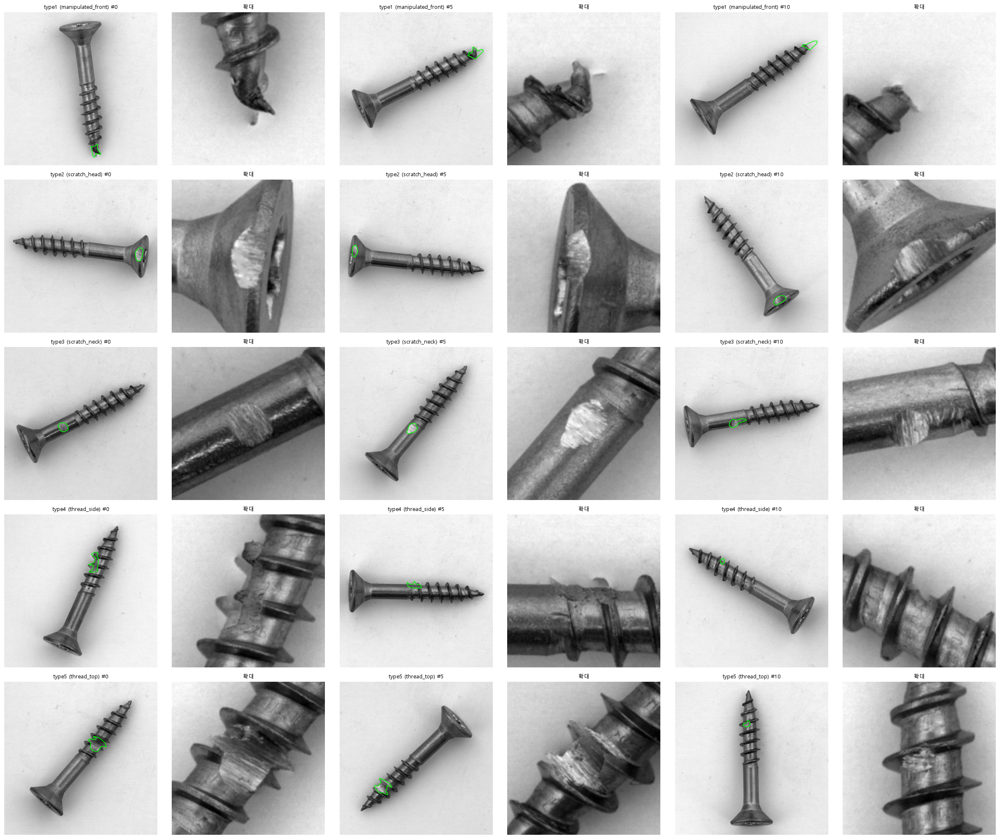

In [5]:
def zoom_slice(shape, c, half=110):
    x, y = int(c[0]), int(c[1])
    x0 = int(np.clip(x - half, 0, shape[1] - 2 * half)); y0 = int(np.clip(y - half, 0, shape[0] - 2 * half))
    return slice(y0, y0 + 2 * half), slice(x0, x0 + 2 * half)

K = 3
fig, axs = plt.subplots(len(synth.TYPES), 2 * K, figsize=(4 * 2 * K, 4 * len(synth.TYPES)))
for i, t in enumerate(synth.TYPES):
    for j in range(K):
        rec = pool[t][j * 5 % len(pool[t])]
        img, m = synth.read_gray(rec["path"]), synth.read_gray(rec["mask"]) > 0
        ys, xs = np.nonzero(m)
        sl = zoom_slice(img.shape, (xs.mean(), ys.mean()))
        axs[i, 2 * j].imshow(img, cmap="gray"); axs[i, 2 * j].contour(m, levels=[0.5], colors="lime", linewidths=1)
        axs[i, 2 * j].set_title(f"{t} ({synth.TYPE_FOLDER[t]}) #{j*5}", fontsize=9)
        axs[i, 2 * j + 1].imshow(img[sl], cmap="gray"); axs[i, 2 * j + 1].set_title("확대", fontsize=9)
for a in axs.ravel(): a.axis("off")
plt.tight_layout(); plt.show()

## 4. 학습 · 평가 함수

baseline(`experiments/supervised/localization_eval.py`)과 같은 설정: Adam(lr 1e-4), `CrossEntropyLoss(weight=[1, 2.0])`, 40 epoch,
**val F2 최고 epoch 의 가중치**를 쓰고 patience 10 으로 early stop. 이미지는 첫 변환(`Resize(256)`)까지 한 번만 처리해 메모리에 캐시해서 속도를 높인다(결과는 동일).

In [6]:
assert isinstance(train_transform.transforms[0], transforms.Resize)
TRAIN_TF = transforms.Compose(train_transform.transforms[1:])   # Resize(256) 이후 증강
VAL_TF = transforms.Compose(val_transform.transforms[1:])
_resize = train_transform.transforms[0]
_CACHE = {}
def cached_img(path):
    if path not in _CACHE:
        _CACHE[path] = _resize(Image.open(path).convert("RGB"))
    return _CACHE[path]

class CachedDS(Dataset):
    def __init__(self, recs, tf): self.recs, self.tf = recs, tf
    def __len__(self): return len(self.recs)
    def __getitem__(self, i):
        r = self.recs[i]
        return self.tf(cached_img(r["path"])), r["label"]

def loader(recs, train):
    return DataLoader(CachedDS(recs, TRAIN_TF if train else VAL_TF), batch_size=BATCH, shuffle=train, num_workers=0)

val_loader = loader(val_recs, False)
test_loader = loader(test_recs, False)

def train_one(ratio, seed):
    set_seed(seed)
    synth_recs = synth.take(pool, ALLOC[ratio]) if ratio > 0 else []
    train_recs = tr_recs + synth_recs
    assert not (P(synth_recs) & (P(val_recs) | P(test_recs)))
    train_loader = loader(train_recs, True)
    model = build_model_bin("resnet18").to(device)
    crit = nn.CrossEntropyLoss(weight=torch.tensor([1.0, BAD_WEIGHT]).to(device))
    opt = optim.Adam(model.parameters(), lr=LR)
    best_f2, best_ep, best_state, bad = 0.0, 0, copy.deepcopy(model.state_dict()), 0
    for ep in range(EPOCHS):
        model.train()
        for imgs, y in train_loader:
            opt.zero_grad()
            loss = crit(model(imgs.to(device)), y.to(device))
            loss.backward(); opt.step()
        model.eval(); yt, yp = [], []
        with torch.no_grad():
            for imgs, y in val_loader:
                yp.extend(model(imgs.to(device)).argmax(1).cpu().numpy()); yt.extend(y.numpy())
        f2 = fbeta_score(yt, yp, beta=2, pos_label=1, zero_division=0)
        if f2 > best_f2:
            best_f2, best_ep, best_state, bad = f2, ep + 1, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
        if bad >= PATIENCE:
            break
    model.load_state_dict(best_state); model.eval()
    return model, best_f2, best_ep, len(train_recs), len(synth_recs)

def evaluate(model):
    yt, yp, pr = [], [], []
    with torch.no_grad():
        for imgs, y in test_loader:
            lg = model(imgs.to(device))
            yp.extend(lg.argmax(1).cpu().numpy()); pr.extend(torch.softmax(lg, 1)[:, 1].cpu().numpy()); yt.extend(y.numpy())
    tn, fp, fn, tp = confusion_matrix(yt, yp, labels=[0, 1]).ravel()
    out = dict(precision=precision_score(yt, yp, zero_division=0), recall=recall_score(yt, yp),
               f2=fbeta_score(yt, yp, beta=2, pos_label=1, zero_division=0), img_auroc=roc_auc_score(yt, pr),
               tn=tn, fp=fp, fn=fn, tp=tp)
    loc = evaluate_localization(model, test_recs, device)                 # 결함 19장 Grad-CAM vs GT
    out.update(pixel_auroc=loc["pixel_auroc"], aupro=loc["aupro"])
    for t, m in evaluate_localization_by_type(model, test_recs, device).items():
        out[f"pa_{t}"] = m["pixel_auroc"]
    return out
print("정의 완료")

정의 완료


## 5. 실행 — (비율 × 시드) 전부 학습 후 평가

결과는 `outputs/synth_exp/runs.csv` 에 한 줄씩 저장되고, 이미 끝난 조합은 건너뛴다. 모델 가중치도 저장(6번 Grad-CAM 비교에 사용).

In [7]:
done = pd.read_csv(RUNS_CSV) if os.path.exists(RUNS_CSV) else pd.DataFrame()
rows = done.to_dict("records")
done_keys = {(float(r["ratio"]), int(r["seed"])) for r in rows}
total = len(RATIOS) * len(SEEDS)

def model_path(ratio, seed): return os.path.join(MODEL_DIR, f"r{ratio:.2f}_s{seed}.pth")

for seed in SEEDS:
    for ratio in RATIOS:
        if (float(ratio), seed) in done_keys:
            continue
        t0 = time.time()
        model, vf2, bep, ntr, nsyn = train_one(ratio, seed)
        torch.save(model.state_dict(), model_path(ratio, seed))
        res = evaluate(model)
        rows.append(dict(ratio=ratio, seed=seed, n_train=ntr, n_synth=nsyn, best_epoch=bep, val_f2=vf2,
                         seconds=round(time.time() - t0), **res))
        pd.DataFrame(rows).to_csv(RUNS_CSV, index=False)
        print(f"[{len(rows):2d}/{total}] ratio={ratio:<4} seed={seed} | val F2 {vf2:.3f} (ep {bep}) | "
              f"test F2 {res['f2']:.3f} R {res['recall']:.3f} P {res['precision']:.3f} | "
              f"pixAUROC {res['pixel_auroc']:.3f} AUPRO {res['aupro']:.3f} | {time.time()-t0:.0f}s")
        del model; torch.cuda.empty_cache()
runs = pd.DataFrame(rows)
print("완료:", len(runs), "runs")

[ 1/20] ratio=0.0  seed=0 | val F2 0.787 (ep 15) | test F2 0.842 R 0.842 P 0.842 | pixAUROC 0.692 AUPRO 0.343 | 49s
[ 2/20] ratio=0.25 seed=0 | val F2 0.935 (ep 35) | test F2 0.914 R 0.895 P 1.000 | pixAUROC 0.841 AUPRO 0.748 | 162s
[ 3/20] ratio=0.5  seed=0 | val F2 0.952 (ep 36) | test F2 0.957 R 0.947 P 1.000 | pixAUROC 0.891 AUPRO 0.850 | 90s
[ 4/20] ratio=1.0  seed=0 | val F2 0.909 (ep 38) | test F2 0.851 R 0.842 P 0.889 | pixAUROC 0.868 AUPRO 0.792 | 124s
[ 5/20] ratio=0.0  seed=1 | val F2 0.874 (ep 18) | test F2 0.625 R 0.579 P 0.917 | pixAUROC 0.782 AUPRO 0.457 | 90s
[ 6/20] ratio=0.25 seed=1 | val F2 0.905 (ep 30) | test F2 0.904 R 0.895 P 0.944 | pixAUROC 0.911 AUPRO 0.848 | 96s
[ 7/20] ratio=0.5  seed=1 | val F2 0.856 (ep 26) | test F2 0.825 R 0.842 P 0.762 | pixAUROC 0.892 AUPRO 0.770 | 80s
[ 8/20] ratio=1.0  seed=1 | val F2 0.841 (ep 35) | test F2 0.798 R 0.789 P 0.833 | pixAUROC 0.952 AUPRO 0.830 | 104s
[ 9/20] ratio=0.0  seed=2 | val F2 0.859 (ep 38) | test F2 0.730 R 0.

## 6. 결과 표 — 합성 비율별 평균 ± 표준편차 (real-only test 55장)

`Δ` 는 합성 없음(0.0) 대비 평균 차이. 표준편차(시드 간 변동)보다 Δ 가 작으면 합성 효과라고 말할 수 없다.

In [8]:
runs = pd.read_csv(RUNS_CSV)
METRICS = [("f2", "Test F2"), ("recall", "Recall"), ("precision", "Precision"), ("img_auroc", "Image AUROC"),
           ("pixel_auroc", "Pixel AUROC (Grad-CAM)"), ("aupro", "AUPRO (Grad-CAM)"), ("val_f2", "Best val F2")]
g = runs.groupby("ratio")
base = g.mean(numeric_only=True).loc[0.0] if 0.0 in g.groups else None
tab = pd.DataFrame(index=sorted(runs["ratio"].unique()))
tab.index.name = "합성 비율"
tab["합성 수"] = g["n_synth"].first()
tab["runs"] = g.size()
for k, name in METRICS:
    m, s = g[k].mean(), g[k].std(ddof=1).fillna(0)
    tab[name] = [f"{m[r]:.3f} ± {s[r]:.3f}" for r in tab.index]
    if base is not None and k in ("f2", "pixel_auroc", "aupro"):
        tab["Δ " + name.split(" ")[0] + (" AUROC" if k == "pixel_auroc" else "")] = [f"{m[r]-base[k]:+.3f}" for r in tab.index]
tab

,합성 수,runs,Test F2,Δ Test,Recall,Precision,Image AUROC,Pixel AUROC (Grad-CAM),Δ Pixel AUROC,AUPRO (Grad-CAM),Δ AUPRO,Best val F2
합성 비율,,,,,,,,,,,,
0.00,0,5,0.778 ± 0.100,+0.000,0.747 ± 0.114,0.952 ± 0.071,0.969 ± 0.021,0.807 ± 0.095,+0.000,0.556 ± 0.181,+0.000,0.867 ± 0.052
0.25,65,5,0.881 ± 0.040,+0.102,0.884 ± 0.044,0.876 ± 0.102,0.959 ± 0.032,0.902 ± 0.043,+0.095,0.808 ± 0.049,+0.252,0.900 ± 0.052
0.50,130,5,0.842 ± 0.065,+0.064,0.842 ± 0.064,0.848 ± 0.099,0.934 ± 0.029,0.876 ± 0.015,+0.069,0.806 ± 0.045,+0.250,0.901 ± 0.036
1.00,260,5,0.821 ± 0.038,+0.043,0.832 ± 0.044,0.795 ± 0.106,0.899 ± 0.041,0.903 ± 0.040,+0.096,0.815 ± 0.030,+0.260,0.864 ± 0.032


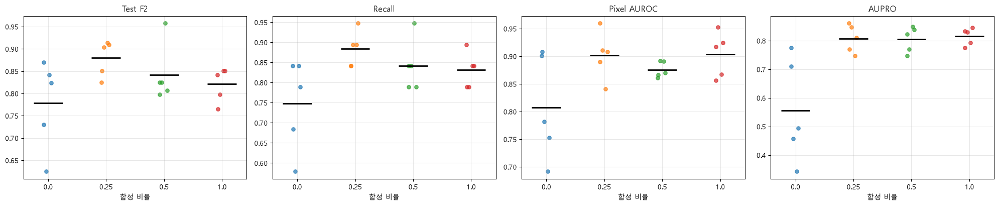

,type1\nmanipulated_front,type2\nscratch_head,type3\nscratch_neck,type4\nthread_side,type5\nthread_top
ratio,,,,,
0.00,0.669,0.922,0.918,0.538,0.860
0.25,0.950,0.966,0.981,0.586,0.974
0.50,0.902,0.975,0.988,0.438,0.976
1.00,0.967,0.952,0.981,0.589,0.974


In [9]:
# 시드별 점 + 평균선
fig, axs = plt.subplots(1, 4, figsize=(20, 4.2))
for a, (k, name) in zip(axs, [("f2", "Test F2"), ("recall", "Recall"), ("pixel_auroc", "Pixel AUROC"), ("aupro", "AUPRO")]):
    rs = sorted(runs["ratio"].unique())
    for i, r in enumerate(rs):
        v = runs[runs["ratio"] == r][k].values
        a.scatter(np.full(len(v), i) + np.random.default_rng(0).uniform(-.08, .08, len(v)), v, alpha=.7, s=28)
        a.hlines(v.mean(), i - .25, i + .25, color="k", lw=2)
    a.set_xticks(range(len(rs))); a.set_xticklabels([str(r) for r in rs]); a.set_xlabel("합성 비율"); a.set_title(name); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

# 유형별 Pixel AUROC (시드 평균)
pa = runs.groupby("ratio")[[f"pa_{t}" for t in synth.TYPES]].mean()
pa.columns = [f"{t}\n{synth.TYPE_FOLDER[t]}" for t in synth.TYPES]
pa.round(3)

## 7. Grad-CAM 비교 — 같은 test 이미지를 비율별 모델이 어디를 보는지

모델은 같은 시드끼리 비교한다(`VIZ_SEED`). 열: 원본 / GT 마스크 / 비율별 Grad-CAM(타깃 = bad 클래스). 제목의 `p`는 bad 확률.
선택 규칙은 **유형별 test 첫 장(고정 규칙)** — 보기 좋은 장면만 고르지 않는다. 마지막 행은 정상 1장(정상에서 bad 근거를 어디서 찾는지).

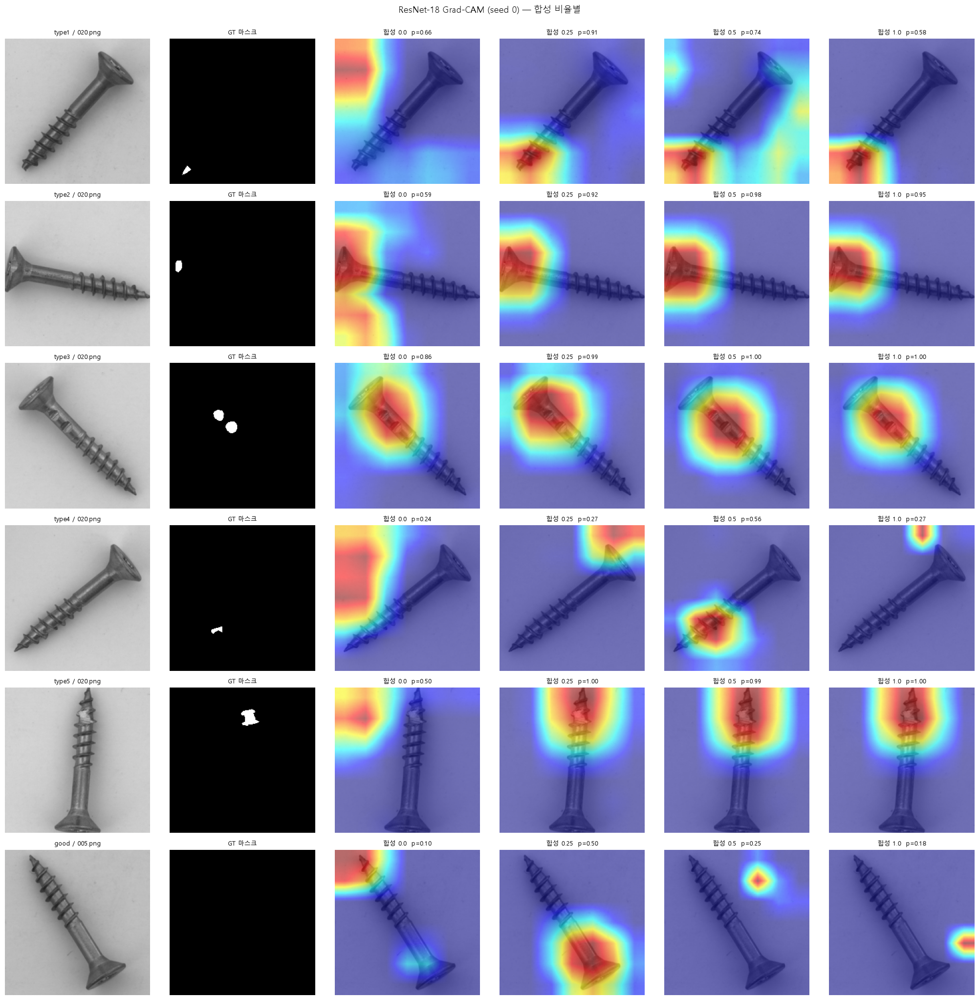

In [10]:
VIZ_SEED = SEEDS[0]
VIZ_RATIOS = [r for r in RATIOS if os.path.exists(model_path(r, VIZ_SEED))]

_models = {}
def get_model(ratio, seed):
    k = (ratio, seed)
    if k not in _models:
        m = build_model_bin("resnet18").to(device)
        m.load_state_dict(torch.load(model_path(ratio, seed), map_location=device)); m.eval()
        _models[k] = (m, GradCAM(model=m, target_layers=[m.layer4[-1]]))
    return _models[k]

def cam_on(ratio, seed, rec):
    m, cam = get_model(ratio, seed)
    x = val_transform(Image.open(rec["path"]).convert("RGB")).unsqueeze(0).to(device)
    heat = cam(input_tensor=x, targets=[ClassifierOutputTarget(1)])[0]
    with torch.no_grad():
        p = torch.softmax(m(x), 1)[0, 1].item()
    img = np.clip(inv_normalize(x.squeeze(0)).cpu().numpy().transpose(1, 2, 0), 0, 1)
    return img, show_cam_on_image(img, heat, use_rgb=True), p

def show_cam_compare(recs, seed=VIZ_SEED, ratios=VIZ_RATIOS):
    fig, axs = plt.subplots(len(recs), 2 + len(ratios), figsize=(3.4 * (2 + len(ratios)), 3.4 * len(recs)))
    axs = np.atleast_2d(axs)
    for i, rec in enumerate(recs):
        mask = load_mask(rec["mask"]) if rec["mask"] else np.zeros((224, 224), np.float32)
        img, _, _ = cam_on(ratios[0], seed, rec)
        axs[i, 0].imshow(img); axs[i, 0].set_title(f"{rec['type']} / {os.path.basename(rec['path'])}", fontsize=9)
        axs[i, 1].imshow(mask, cmap="gray", vmin=0, vmax=1); axs[i, 1].set_title("GT 마스크", fontsize=9)
        for j, r in enumerate(ratios):
            _, ov, p = cam_on(r, seed, rec)
            axs[i, 2 + j].imshow(ov); axs[i, 2 + j].set_title(f"합성 {r}  p={p:.2f}", fontsize=9)
    for a in axs.ravel(): a.axis("off")
    fig.suptitle(f"ResNet-18 Grad-CAM (seed {seed}) — 합성 비율별", fontsize=13, y=1.0)
    plt.tight_layout(); plt.show()

first_per_type = [next(r for r in test_recs if r["type"] == t) for t in synth.TYPES]
one_good = [next(r for r in test_recs if r["type"] == "good")]
show_cam_compare(first_per_type + one_good)

### (선택) test 결함 19장 전부 — 5장씩 끊어서

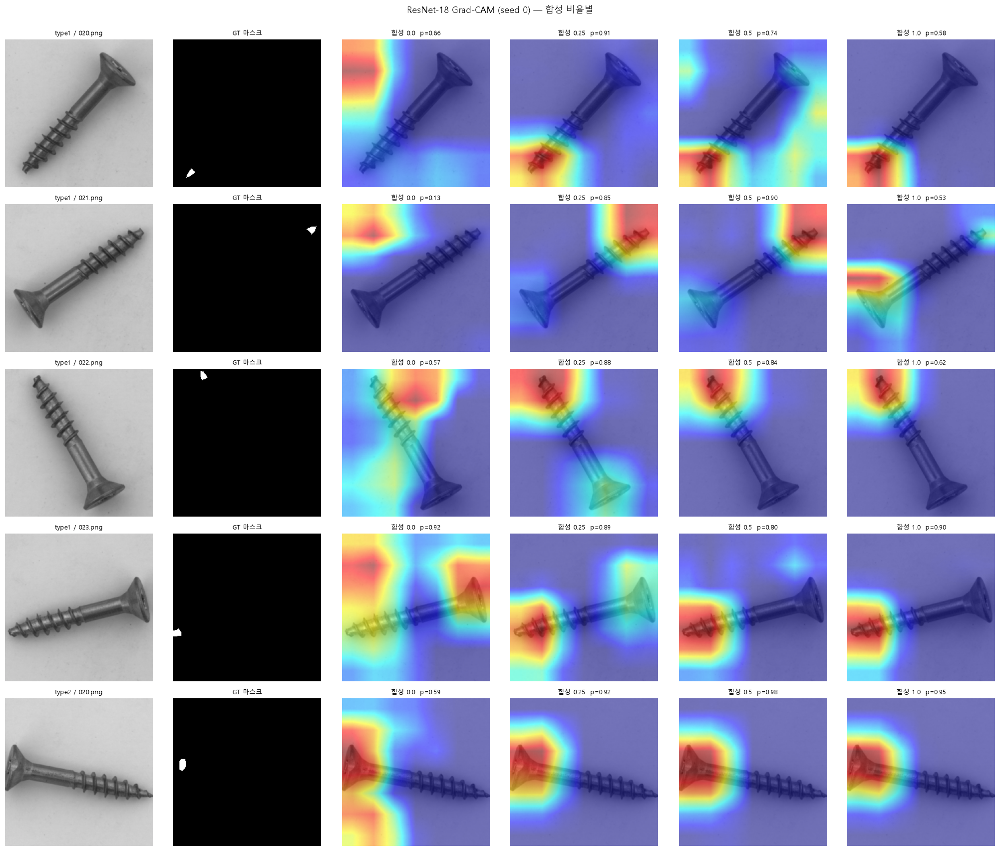

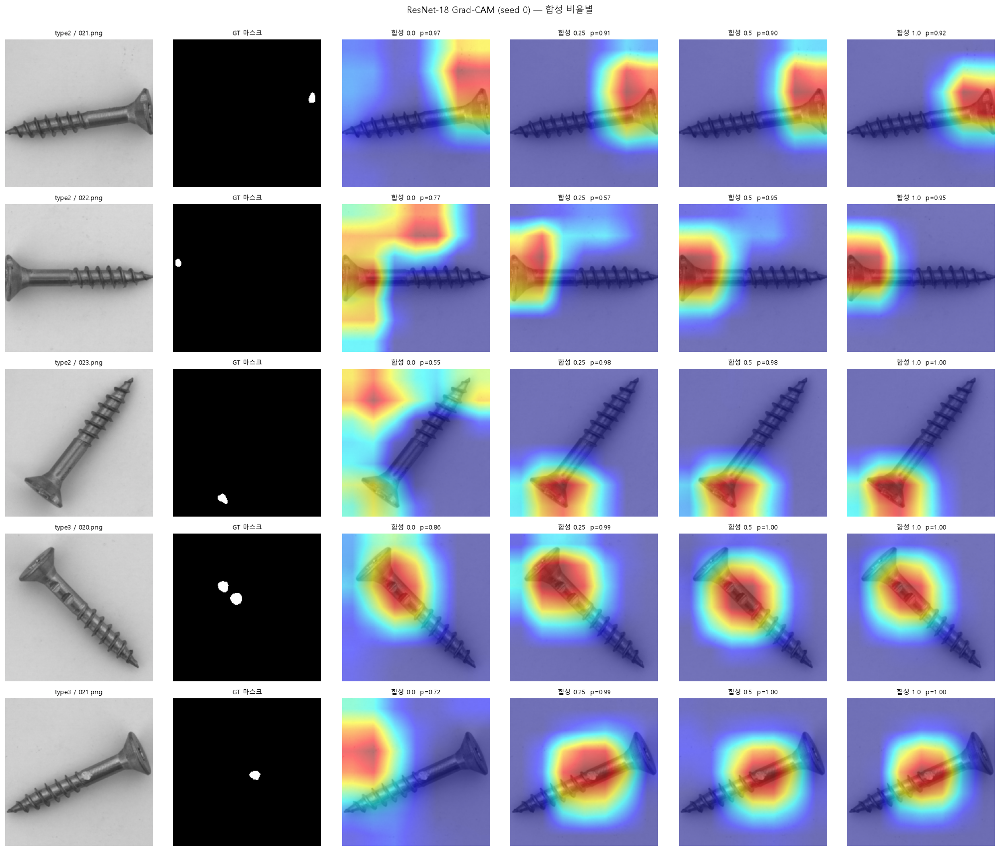

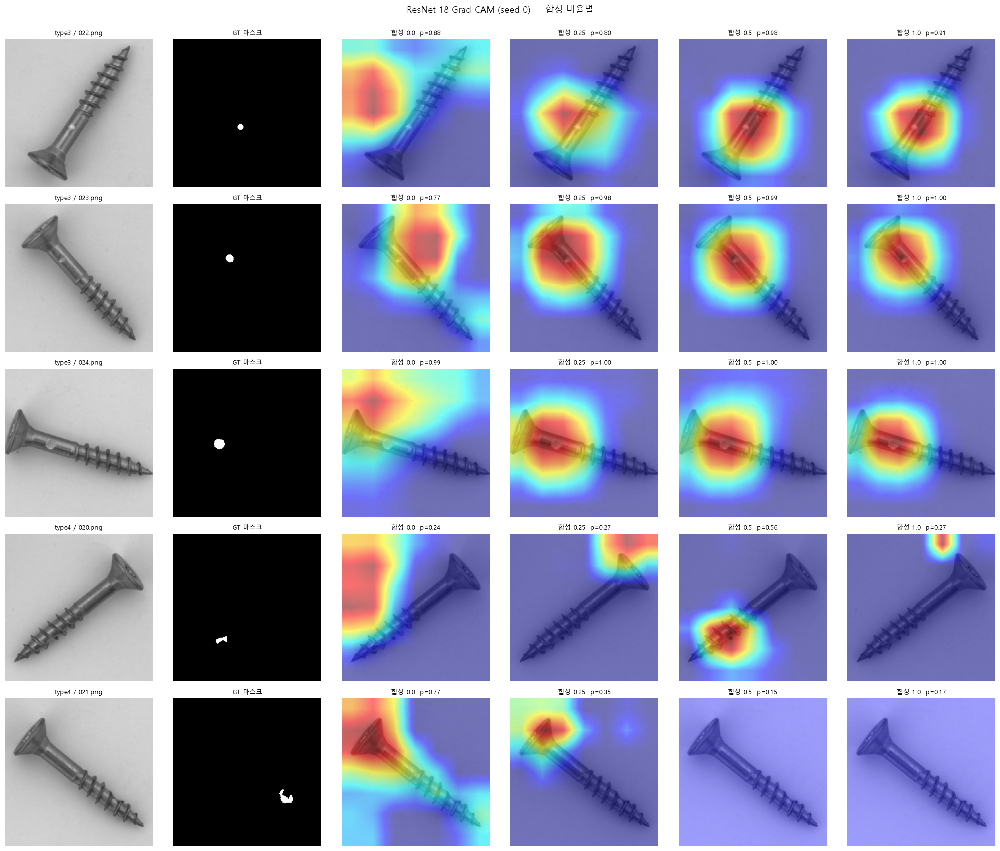

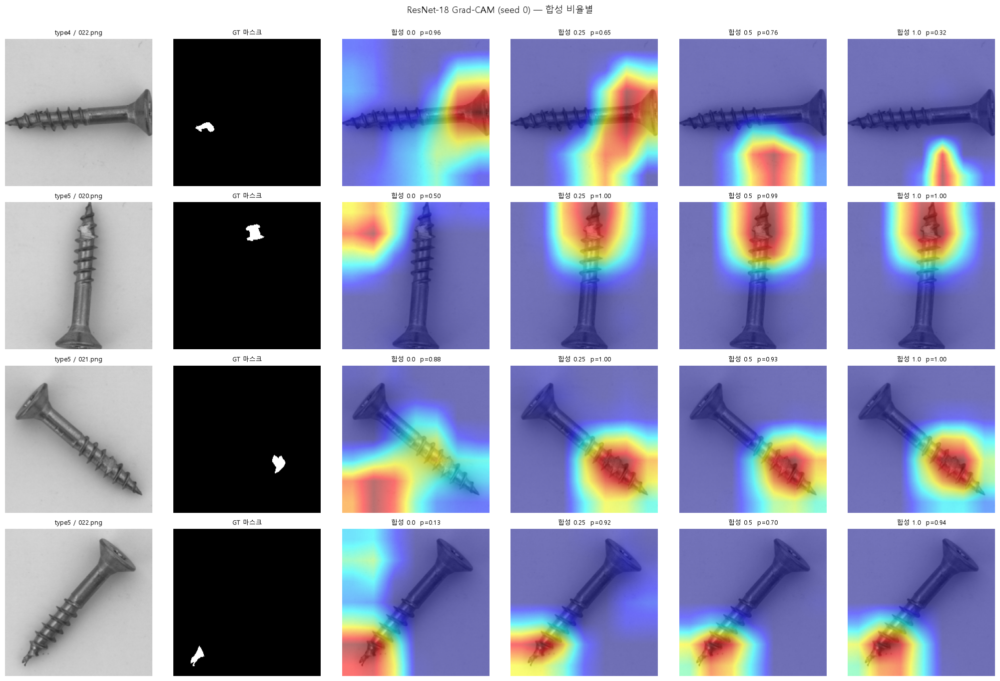

: 

In [ ]:
all_defects = [r for r in test_recs if r["label"] == 1]
for k in range(0, len(all_defects), 5):
    show_cam_compare(all_defects[k:k + 5])

## 8. 해석 시 주의

- test 결함이 **19장**이라 한 이미지가 F2 를 크게 흔든다. 시드 간 표준편차보다 작은 Δ 는 효과로 해석하지 않는다.
- 합성 비율이 커질수록 합성(real 80장 소스를 재사용)이 학습 결함의 대부분이 된다 — 성능이 **오히려 떨어지면** 모델이 이식 경계/질감 같은 합성 흔적을 결함 신호로 학습했을 가능성을 의심한다(Grad-CAM 이 결함이 아닌 경계에 반응하는지 7번에서 확인).
- Grad-CAM 위치 지표는 결함 19장 기준이며 PatchCore(119장)와 직접 비교하지 않는다(프로젝트 방침).